# Tiền xử lý và huấn luyện MNIST

**Nhóm 03 · Naive Bayes · k-NN · SVM · Random Forest · CNN**

Dữ liệu: **50.000 train / 10.000 validation / 10.000 test**. PCA chỉ fit trên train.
Mỗi mô hình có một cell huấn luyện và một bảng Precision, Recall, F1, số ảnh sai sau khi train.
Precision, Recall và F1 được tính theo macro trên 10 lớp.

Các mô hình ML dùng cấu hình đã chọn theo validation. CNN bắt đầu với giới hạn 70 epoch;
nếu chưa dừng sớm thì tự tăng giới hạn thêm 20 epoch, tiếp tục đến khi early stopping kích hoạt.
Checkpoint có validation loss thấp nhất được dùng để đánh giá test.

Chạy **Run All**. Thư viện: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `opencv-python-headless`, `torch`.

## 1. Thư viện và dữ liệu

In [1]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits
SEED = 42
thread_limit = threadpool_limits(limits=4)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
import copy, json, joblib, cv2, torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
CPU_THREADS = 4
torch.set_num_threads(CPU_THREADS)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = Path('mnist_best_models')
OUT.mkdir(exist_ok=True)
paths = [Path('mnist.npz'), Path('data/mnist.npz'), Path('../data/mnist.npz')]
if Path('/kaggle/input').exists():
    paths += list(Path('/kaggle/input').rglob('mnist.npz'))
data_path = next((p for p in paths if p.is_file()), Path('mnist.npz'))
if not data_path.exists():
    urllib.request.urlretrieve('https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz',
        data_path)
with np.load(data_path, allow_pickle=False) as data:
    images, labels = (data['x_train'], data['y_train'])
    test_images, test_labels = (data['x_test'], data['y_test'])
assert images.shape == (60000, 28, 28) and test_images.shape == (10000, 28, 28)
assert not np.isnan(images).any() and set(np.unique(labels)) == set(range(10))
x_train, x_val, y_train, y_val = train_test_split(images.astype(np.float32) / 255,
    labels,
    test_size=10000,
    stratify=labels,
    random_state=SEED)
x_test = test_images.astype(np.float32) / 255
a_train, a_val, a_test = [x.reshape(-1, 784) for x in (x_train, x_val, x_test)]
print(f'Train {len(y_train):,} | Validation {len(y_val):,} | Test {len(test_labels):,} | CNN: {DEVICE}')
results, predictions, chosen_params, val_scores = {}, {}, {}, {}
from sklearn.metrics import ConfusionMatrixDisplay

Train 50,000 | Validation 10,000 | Test 10,000 | CNN: cpu


## 2. Tiền xử lý

Naive Bayes và Random Forest dùng pixel chuẩn hóa [0, 1]. k-NN và SVM dùng Deskew + PCA 95%.
CNN nhận ảnh chuẩn hóa có kích thước 1 × 28 × 28.

In [2]:
def deskew(batch):
    result = np.empty_like(batch)
    for i, image in enumerate(batch):
        moment = cv2.moments(image)
        skew = moment['mu11'] / moment['mu02'] if abs(moment['mu02']) >= 0.01 else 0
        matrix = np.float32([[1, skew, -14 * skew], [0, 1, 0]])
        result[i] = cv2.warpAffine(image, matrix, (28, 28), flags=cv2.WARP_INVERSE_MAP | cv2.INTER_LINEAR)
    return result.reshape(-1, 784)
pca = PCA(n_components=0.95, random_state=SEED)
b_train = pca.fit_transform(deskew(x_train))
b_val = pca.transform(deskew(x_val))
b_test = pca.transform(deskew(x_test))
joblib.dump(pca, OUT / 'pca.joblib', compress=3)
print(f'k-NN và SVM: Deskew + PCA, 784 → {pca.n_components_} chiều.')

k-NN và SVM: Deskew + PCA, 784 → 113 chiều.


## 3. Hàm đánh giá và huấn luyện CNN

In [3]:
def report_model(name, val_pred, test_pred, params):
    precision, recall, f1, _ = precision_recall_fscore_support(
        test_labels, test_pred, average='macro', zero_division=0
    )
    scores = {
        'Precision (%)': precision * 100,
        'Recall (%)': recall * 100,
        'F1 (%)': f1 * 100,
        'Số ảnh sai': int((test_pred != test_labels).sum()),
    }
    val_scores[name] = accuracy_score(y_val, val_pred)
    test_acc = accuracy_score(test_labels, test_pred)
    print(f'Tham số: {params}')
    print(f'Validation Accuracy: {val_scores[name]:.2%} | Test Accuracy: {test_acc:.2%}')
    display(pd.DataFrame([scores], index=[name]).round(2))
    fig, ax = plt.subplots(figsize=(5.5, 4.6))
    ConfusionMatrixDisplay.from_predictions(
        test_labels, test_pred, labels=np.arange(10), display_labels=np.arange(10),
        cmap='Blues', values_format='d', colorbar=False, ax=ax
    )
    ax.set(title=f'Confusion matrix · {name}', xlabel='Dự đoán', ylabel='Nhãn thật')
    plt.tight_layout()
    plt.show()
    results[name] = {'Val Acc (%)': val_scores[name] * 100, 'Test Acc (%)': test_acc * 100, **scores}
    predictions[name], chosen_params[name] = test_pred, params
    pd.DataFrame.from_dict(results, orient='index').rename_axis('Mô hình').to_csv(OUT / 'results.csv')


def make_loader(x, y, batch_size, shuffle=False):
    dataset = TensorDataset(torch.from_numpy(x).unsqueeze(1), torch.from_numpy(y).long())
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


def run_epoch(loader, training):
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if training:
                optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            total += len(y)
    return total_loss / total, correct / total

## 4. Naive Bayes

Tham số: BernoulliNB, alpha=1.0, binarize=0.2
Validation Accuracy: 83.08% | Test Accuracy: 84.46%


,Precision (%),Recall (%),F1 (%),Số ảnh sai
Naive Bayes,84.58,84.2,84.27,1554


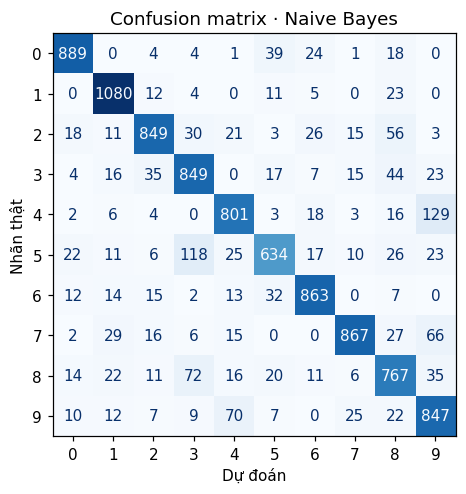

In [4]:
nb = BernoulliNB(alpha=1.0, binarize=0.2)
nb.fit(a_train, y_train)
joblib.dump(nb, OUT / 'Naive_Bayes.joblib', compress=3)
report_model('Naive Bayes', nb.predict(a_val), nb.predict(a_test),
             'BernoulliNB, alpha=1.0, binarize=0.2')

## 5. k-NN

Tham số: k=3, weights=distance, Deskew + PCA 95%
Validation Accuracy: 97.93% | Test Accuracy: 98.06%


,Precision (%),Recall (%),F1 (%),Số ảnh sai
k-NN,98.06,98.04,98.05,194


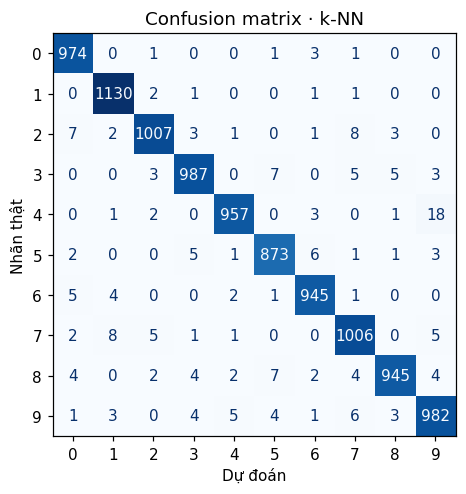

In [5]:
knn = KNeighborsClassifier(n_neighbors=3, weights='distance', n_jobs=CPU_THREADS)
knn.fit(b_train, y_train)
joblib.dump(knn, OUT / 'k-NN.joblib', compress=3)
report_model('k-NN', knn.predict(b_val), knn.predict(b_test),
             'k=3, weights=distance, Deskew + PCA 95%')

## 6. SVM

Tham số: kernel=rbf, C=5, gamma=scale, Deskew + PCA 95%
Validation Accuracy: 98.68% | Test Accuracy: 98.79%


,Precision (%),Recall (%),F1 (%),Số ảnh sai
SVM,98.78,98.79,98.78,121


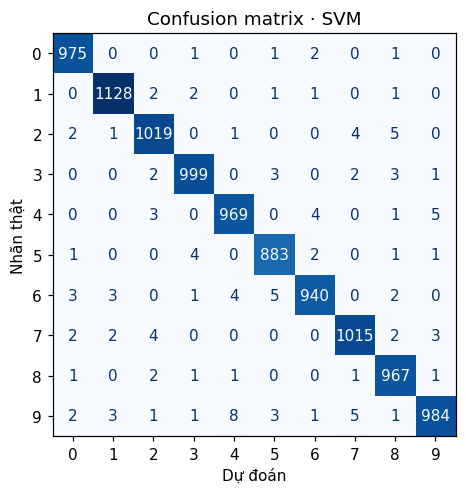

In [6]:
svm = SVC(C=5, kernel='rbf', gamma='scale', cache_size=512)
svm.fit(b_train, y_train)
joblib.dump(svm, OUT / 'SVM.joblib', compress=3)
report_model('SVM', svm.predict(b_val), svm.predict(b_test),
             'kernel=rbf, C=5, gamma=scale, Deskew + PCA 95%')

## 7. Random Forest

Tham số: n_estimators=150, max_features=sqrt, max_depth=None, random_state=42
Validation Accuracy: 96.73% | Test Accuracy: 96.99%


,Precision (%),Recall (%),F1 (%),Số ảnh sai
Random Forest,96.98,96.97,96.97,301


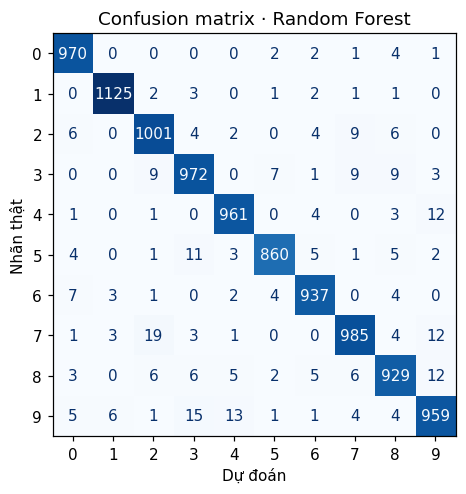

In [7]:
rf = RandomForestClassifier(n_estimators=150, max_features='sqrt',
                            random_state=SEED, n_jobs=CPU_THREADS)
rf.fit(a_train, y_train)
joblib.dump(rf, OUT / 'Random_Forest.joblib', compress=3)
report_model('Random Forest', rf.predict(a_val), rf.predict(a_test),
             'n_estimators=150, max_features=sqrt, max_depth=None, random_state=42')

## 8. CNN

Adam: LR ban đầu **0,001**, weight decay **0,0001**, batch size **64**.
LR giảm một nửa sau 2 epoch liên tiếp không cải thiện validation loss, thấp nhất **0,00001**.
Early stopping: **patience = 3**, **min_delta = 0,0001**.

Mỗi dòng log: epoch/giới hạn | LR | train loss, accuracy | validation loss, accuracy.

CNN: 160,074 tham số | Giới hạn ban đầu: 70 epoch
01/70 | LR 0.001000 | train 0.1650, 95.03% | val 0.0547, 98.28%
02/70 | LR 0.001000 | train 0.0612, 98.09% | val 0.0416, 98.71%
03/70 | LR 0.001000 | train 0.0456, 98.56% | val 0.0430, 98.68%
04/70 | LR 0.001000 | train 0.0412, 98.70% | val 0.0410, 98.87%
05/70 | LR 0.001000 | train 0.0349, 98.92% | val 0.0342, 98.90%
06/70 | LR 0.001000 | train 0.0294, 99.05% | val 0.0357, 98.89%
07/70 | LR 0.001000 | train 0.0276, 99.11% | val 0.0314, 99.10%
08/70 | LR 0.001000 | train 0.0266, 99.16% | val 0.0346, 98.86%
09/70 | LR 0.001000 | train 0.0251, 99.20% | val 0.0299, 99.08%
10/70 | LR 0.001000 | train 0.0242, 99.24% | val 0.0316, 99.03%
11/70 | LR 0.001000 | train 0.0221, 99.27% | val 0.0330, 98.99%
12/70 | LR 0.000500 | train 0.0117, 99.61% | val 0.0276, 99.17%
13/70 | LR 0.000500 | train 0.0106, 99.68% | val 0.0281, 99.22%
14/70 | LR 0.000500 | train 0.0092, 99.71% | val 0.0250, 99.28%
15/70 | LR 0.000500 | train 0.0110, 99.64% | val 0.032

,Precision (%),Recall (%),F1 (%),Số ảnh sai
CNN,99.43,99.43,99.43,56


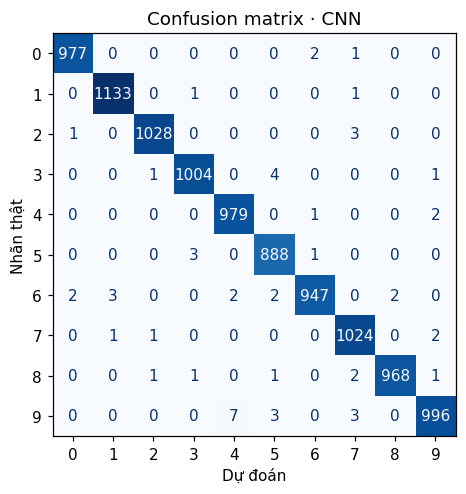

In [8]:
INITIAL_EPOCHS, EXTEND_EPOCHS = 70, 20
PATIENCE, MIN_DELTA = 3, 1e-4
torch.manual_seed(SEED)
model = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(64, 128, 3), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
    nn.Dropout(0.4), nn.Linear(512, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 10),
).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=1, threshold=MIN_DELTA,
    threshold_mode='abs', min_lr=1e-5
)
train_loader = make_loader(x_train, y_train, 64, shuffle=True)
val_loader = make_loader(x_val, y_val, 256)
print(f'CNN: {sum(p.numel() for p in model.parameters()):,} tham số | Giới hạn ban đầu: {INITIAL_EPOCHS} epoch')

history, best_loss, stop_loss, wait = [], float('inf'), float('inf'), 0
epoch, epoch_limit = 0, INITIAL_EPOCHS
while True:
    if epoch >= epoch_limit:
        epoch_limit += EXTEND_EPOCHS
        print(f'Tăng giới hạn lên {epoch_limit} epoch.')
    epoch += 1
    lr = optimizer.param_groups[0]['lr']
    train_loss, train_acc = run_epoch(train_loader, True)
    val_loss, val_acc = run_epoch(val_loader, False)
    scheduler.step(val_loss)
    history.append({'epoch': epoch, 'lr': lr, 'train_loss': train_loss,
                    'val_loss': val_loss, 'train_acc': train_acc, 'val_acc': val_acc})
    print(f'{epoch:02d}/{epoch_limit} | LR {lr:.6f} | train {train_loss:.4f}, {train_acc:.2%}'
          f' | val {val_loss:.4f}, {val_acc:.2%}', flush=True)
    if val_loss < best_loss:
        best_loss, best_epoch = val_loss, epoch
        best_weights = copy.deepcopy(model.state_dict())
    if val_loss < stop_loss - MIN_DELTA:
        stop_loss, wait = val_loss, 0
    else:
        wait += 1
    pd.DataFrame(history).to_csv(OUT / 'cnn_history.csv', index=False)
    if wait >= PATIENCE:
        print(f'Early stopping tại epoch {epoch}.')
        break

model.load_state_dict(best_weights)
model.eval()
torch.save(best_weights, OUT / 'CNN.pt')
print(f'Đã khôi phục checkpoint epoch {best_epoch}, validation loss {best_loss:.4f}.')
val_pred, test_pred = [], []
with torch.no_grad():
    for loader, output in [(val_loader, val_pred), (make_loader(x_test, test_labels, 256), test_pred)]:
        for x, _ in loader:
            output.append(model(x.to(DEVICE)).argmax(1).cpu().numpy())
report_model('CNN', np.concatenate(val_pred), np.concatenate(test_pred),
             f'Adam, LR đầu=0.001, weight_decay=0.0001, batch=64, checkpoint epoch {best_epoch}')

## 9. Đường học CNN và lưu kết quả

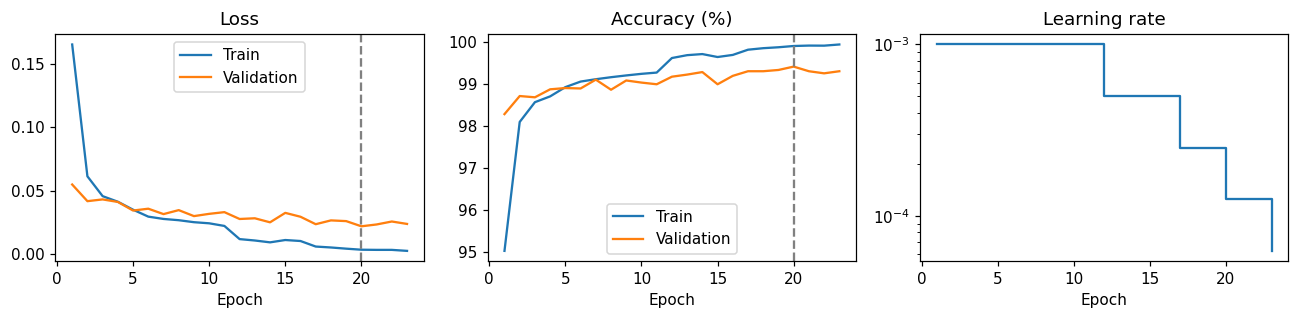

Đã lưu 5 mô hình, lịch sử CNN và kết quả tại mnist_best_models.


In [9]:
h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].plot(h.epoch, h.train_loss, label='Train')
axes[0].plot(h.epoch, h.val_loss, label='Validation')
axes[0].set(title='Loss', xlabel='Epoch')
axes[0].legend()
axes[1].plot(h.epoch, h.train_acc * 100, label='Train')
axes[1].plot(h.epoch, h.val_acc * 100, label='Validation')
axes[1].set(title='Accuracy (%)', xlabel='Epoch')
axes[1].legend()
axes[2].step(h.epoch, h.lr, where='post')
axes[2].set(title='Learning rate', xlabel='Epoch', yscale='log')
for ax in axes[:2]:
    ax.axvline(best_epoch, color='gray', linestyle='--')
plt.tight_layout()
plt.show()
np.savez_compressed(OUT / 'predictions.npz', y_true=test_labels, **predictions)
config = {
    'seed': SEED, 'train': 50000, 'validation': 10000, 'test': 10000,
    'parameters': chosen_params, 'cnn_best_epoch': best_epoch, 'cnn_best_val_loss': best_loss,
    'cnn_initial_epoch_limit': INITIAL_EPOCHS, 'cnn_final_epoch_limit': epoch_limit,
    'cnn_extend_epochs': EXTEND_EPOCHS, 'cnn_epochs_run': epoch,
    'cnn_stop_reason': 'early_stopping', 'cnn_early_stopping_patience': PATIENCE,
    'cnn_min_delta': MIN_DELTA, 'cnn_initial_lr': 0.001,
    'cnn_scheduler_factor': 0.5, 'cnn_scheduler_patience': 1, 'cnn_min_lr': 1e-5,
    'selected_by_validation': max(val_scores, key=val_scores.get),
}
(OUT / 'selected_config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Đã lưu 5 mô hình, lịch sử CNN và kết quả tại {OUT}.')

## 10. So sánh các mô hình

Các chỉ số được tính trên cùng 10.000 ảnh test. Precision, Recall và F1 dùng trung bình macro trên 10 lớp.

,Test Acc (%),Precision (%),Recall (%),F1 (%),Số ảnh sai
Mô hình,,,,,
Naive Bayes,84.46,84.58,84.20,84.27,1554
k-NN,98.06,98.06,98.04,98.05,194
SVM,98.79,98.78,98.79,98.78,121
Random Forest,96.99,96.98,96.97,96.97,301
CNN,99.44,99.43,99.43,99.43,56


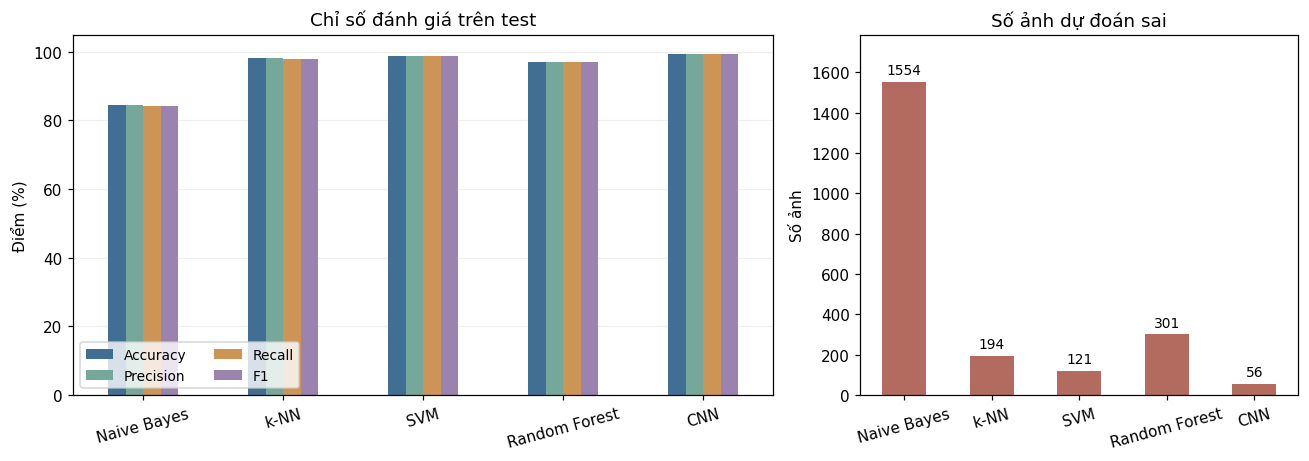

In [10]:
comparison = pd.DataFrame.from_dict(results, orient='index').rename_axis('Mô hình')
columns = ['Test Acc (%)', 'Precision (%)', 'Recall (%)', 'F1 (%)', 'Số ảnh sai']
comparison = comparison[columns]
display(comparison.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={'width_ratios': [1.6, 1]})
scores = comparison[columns[:4]].copy()
scores.columns = ['Accuracy', 'Precision', 'Recall', 'F1']
scores.plot.bar(ax=axes[0], rot=15, color=['#416f94', '#75a89a', '#cc9556', '#9b83b0'])
axes[0].set(title='Chỉ số đánh giá trên test', xlabel='', ylabel='Điểm (%)', ylim=(0, 105))
axes[0].legend(loc='lower left', ncol=2, fontsize=9)
axes[0].grid(axis='y', alpha=0.2)
axes[0].set_axisbelow(True)
comparison['Số ảnh sai'].plot.bar(ax=axes[1], rot=15, color='#b46b5f')
axes[1].set(title='Số ảnh dự đoán sai', xlabel='', ylabel='Số ảnh')
axes[1].set_ylim(0, comparison['Số ảnh sai'].max() * 1.15)
axes[1].bar_label(axes[1].containers[0], fmt='%d', padding=3, fontsize=9)
plt.tight_layout()
plt.show()